# CS620 Research Project — Phase 3: Neural Prediction and Vector Drift

**Workstream A (geometry):** how much does character noise move a *static* text vector?  
**Workstream B (neural prediction):** how does noise change next-token prediction?

> A small vector displacement is **not** proof that meaning was preserved. We measure geometry only.

All results here are **preliminary validation results**; the test split is never opened.
Plan and design decisions: `docs/assignment/Phase-3/PHASE3_PLAN.md`.

| Part | What | Section |
|---|---|---|
| G0 | Config freeze (inherits Phase 2) | 1 |
| G1 | Frozen embedding table **E** + hash | 2 |
| G2 | Select clean spans | 3 |
| G3 | Recover noisy counterparts from the saved edit logs | 4 |
| G4 | Tokenize a span, look up pieces in **E**, mean-pool | 5 |
| G5 | Cosine and Euclidean distance per pair, undefined handling | 6 |
| G6 | 37-row static span audit | 7 |
| G7 | Seed summaries and figure | 8 |
| G8 | Reproduce with `noise_vector_drift.py`, write result files | 9 |
| N0–N1 | Data: two-token contexts, targets, parity with Assignment 2 | 11 |
| N2 | The two networks, parameter counts, order test | 12 |
| N3 | Training and epoch selection | 13 |
| N4–N5 | Scoring 37 conditions × 2 models, noise summaries | 14 |
| N6 | Assignment 2 n-gram control side by side | 15 |
| N7 | Diagnostics, what we can and cannot claim | 16–17 |

## 0. Setup

In [1]:
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd

from src.phase2_config import load_phase2_config, NOISY_DIR, DERIVED_P2_DIR
from src.geometry.embeddings import (load_phase3_config, load_embedding_table, table_sha256,
                                     DERIVED_P3_DIR, RESULTS_P3_DIR)
from src.geometry.spans import select_spans, noisy_span, reassemble_record, whitespace_spans

DERIVED_P3_DIR.mkdir(parents=True, exist_ok=True); RESULTS_P3_DIR.mkdir(parents=True, exist_ok=True)

## 1. G0 — Configuration

Phase 3 reuses the Phase 2 records, noisy files, noise grid and tokenizer revision unchanged; `configs/phase3.yaml`
records only what is new. Nothing about the data is regenerated.

In [2]:
p2 = load_phase2_config(); p3 = load_phase3_config()
print("checkpoint      :", p2.checkpoint, "@", p2.checkpoint_revision[:8])
print("operations      :", p2.operations)
print("rates           :", p2.rates, "(+ one shared clean condition)")
print("corruption seeds:", p2.seeds)
print("span cap        :", p3["geometry"]["span_cap"])
print("phase label     :", p3["label"])

checkpoint      : bert-base-uncased @ 86b5e093
operations      : ['insertion', 'deletion', 'substitution']
rates           : [0.01, 0.05, 0.1, 0.2] (+ one shared clean condition)
corruption seeds: [11, 23, 47]
span cap        : 1000
phase label     : preliminary validation results


## 2. G1 — Extract and freeze the embedding table **E**

`E ∈ ℝ^{|V|×d}`: row `j` is the static vector of token ID `j`. We read **only** BERT's stored
`embeddings.word_embeddings.weight`: no position/segment vectors, no LayerNorm, no transformer layers, no rescaling.
We hash it now; the same hash must come back at the end of the run (*frozen* = never changed).

In [3]:
E = load_embedding_table(p3)
E_hash_before = table_sha256(E)
print("shape         :", E.shape, "(|V| x d)")
print("dtype         :", E.dtype)
print("writeable     :", E.flags.writeable, " <- read-only, any in-place edit raises")
print("row norm      : min %.3f  mean %.3f  max %.3f" % tuple(f(np.linalg.norm(E, axis=1)) for f in (np.min, np.mean, np.max)))
print("SHA-256       :", E_hash_before)
_ = (DERIVED_P3_DIR / "E.sha256").write_text(E_hash_before + "\n")

shape         : (30522, 768) (|V| x d)
dtype         : float32
writeable     : False  <- read-only, any in-place edit raises
row norm      : min 0.766  mean 1.401  max 2.045
SHA-256       : ca6b51539e1d8c14f11e946a2e6f87a2f547aa0f8d17c15f1c92299d51cd8105


**Disclosure.** BERT's checkpoint was pretrained outside this project (BooksCorpus + English Wikipedia), so its
vectors may have seen WikiText-like text. This is not a comparison in which every system learned only from our
small corpus.

## 3. G2 — Select the clean spans

A *span* is a nonempty whitespace-delimited chunk (`\S+`). We keep spans that contain at least one **eligible**
letter (an ASCII letter the noise rule could edit), walking the validation records in their saved order, and stop at 1,000.
Each span keeps its record ID, span index (counting *all* whitespace chunks, kept or not) and character offsets.

In [4]:
records = [json.loads(l) for l in open(DERIVED_P2_DIR / "val_sample.jsonl")]
by_id = {r["record_id"]: r for r in records}
spans = select_spans(records, p3["geometry"]["span_cap"], p2.protected_spans)

# offsets must slice back to the clean text
assert all(by_id[s.record_id]["text"][s.char_start:s.char_end] == s.text for s in spans)
n_rec = len({s.record_id for s in spans}); n_art = len({s.article_id for s in spans})
print(f"selected spans : {len(spans)}")
print(f"from           : {n_rec} records, {n_art} article(s)  (of {len(records)} records in the validation sample)")
print("first 6        :", [(s.span_id, s.text) for s in spans[:6]])
pd.DataFrame([s.__dict__ for s in spans]).to_json(DERIVED_P3_DIR / "geometry_spans.jsonl", orient="records", lines=True)

selected spans : 1000
from           : 22 records, 2 article(s)  (of 500 records in the validation sample)
first 6        : [('wt2-valid-000007|s0', 'Homarus'), ('wt2-valid-000007|s1', 'gammarus'), ('wt2-valid-000007|s2', 'is'), ('wt2-valid-000007|s3', 'a'), ('wt2-valid-000007|s4', 'large'), ('wt2-valid-000007|s5', 'crustacean')]


**Limitation to carry into the write-up:** the first 1,000 spans come from only the first few records, so this is a
narrow slice of the validation sample, not a random one. The assignment fixes this rule; we report how narrow it is.

## 4. G3 — Recover each span's noisy counterpart

We do **not** pair "n-th clean subword with n-th noisy subword": noise can split or merge pieces. The a2_default rule
edits only letters and never whitespace, so every clean span has exactly one noisy counterpart. We replay the saved
edit log on that span's characters. If every letter is deleted the counterpart is the explicit empty string `""`.

**Check:** rebuild each whole record from its spans and compare with the manifest's `noisy_text`, in all 37 conditions.

In [5]:
conditions = ["clean"] + [f"{op}-p{p:.2f}-s{s}" for op in ("ins","del","sub") for p in p2.rates for s in p2.seeds]
cond_files = {c: NOISY_DIR / f"{c}.jsonl" for c in conditions}
assert all(f.exists() for f in cond_files.values()), "missing noisy file"
assert len(conditions) == 37

used = sorted({s.record_id for s in spans})
rows, mismatches = [], 0
for c in conditions:
    manifest = {}
    for l in open(cond_files[c]):
        r = json.loads(l)
        if r["record_id"] in used: manifest[r["record_id"]] = r
    # whole-record check (all spans of the record, not only the selected ones)
    for rid in used:
        if reassemble_record(by_id[rid]["text"], manifest[rid]["operation_log"]) != manifest[rid]["noisy_text"]:
            mismatches += 1
    for s in spans:
        log = manifest[s.record_id]["operation_log"]
        rows.append((c, s.span_id, s.text, noisy_span(by_id[s.record_id]["text"], log, s.char_start, s.char_end)))

pairs = pd.DataFrame(rows, columns=["condition_id", "span_id", "clean_span", "noisy_span"])
print("conditions            :", len(conditions))
print("records checked       :", len(used), "x", len(conditions), "=", len(used)*len(conditions))
print("reassembly mismatches :", mismatches, " (must be 0)")
print("paired span rows      :", len(pairs), "= 1000 spans x 37 conditions")
assert mismatches == 0 and len(pairs) == len(spans) * 37

conditions            : 37
records checked       : 22 x 37 = 814
reassembly mismatches : 0  (must be 0)
paired span rows      : 37000 = 1000 spans x 37 conditions


In [6]:
# what noise does to spans, per condition family
pairs["changed"] = pairs.clean_span != pairs.noisy_span
pairs["is_empty"] = pairs.noisy_span == ""
pairs["op"] = pairs.condition_id.str.split("-").str[0]
pairs["p"] = pairs.condition_id.str.extract(r"p([\d.]+)")[0].astype(float)
(pairs.groupby(["op", "p"]).agg(spans=("span_id", "size"), changed=("changed", "mean"), empty=("is_empty", "sum"))
      .rename(columns={"changed": "share_changed", "empty": "empty_noisy_spans"}).round(3))

spans  share_changed  empty_noisy_spans
op  p                                            
del 0.01   3000          0.045                  0
    0.05   3000          0.207                  3
    0.10   3000          0.375                 16
    0.20   3000          0.600                 43
ins 0.01   3000          0.045                  0
    0.05   3000          0.204                  0
    0.10   3000          0.379                  0
    0.20   3000          0.613                  0
sub 0.01   3000          0.046                  0
    0.05   3000          0.210                  0
    0.10   3000          0.368                  0
    0.20   3000          0.597                  0

In [7]:
# a few concrete pairs, to see what we will embed next
pd.concat([pairs[(pairs.condition_id == c) & pairs.changed].head(4) for c in ("ins-p0.10-s11", "del-p0.20-s11", "sub-p0.10-s11")]
         )[["condition_id", "span_id", "clean_span", "noisy_span"]].reset_index(drop=True)

,condition_id,span_id,clean_span,noisy_span
0,ins-p0.10-s11,wt2-valid-000007|s1,gammarus,gdammarus
1,ins-p0.10-s11,wt2-valid-000007|s2,is,isj
2,ins-p0.10-s11,wt2-valid-000007|s5,crustacean,cruistacean
3,ins-p0.10-s11,wt2-valid-000007|s9,body,bodyv
4,del-p0.20-s11,wt2-valid-000007|s1,gammarus,gmars
5,del-p0.20-s11,wt2-valid-000007|s2,is,i
6,del-p0.20-s11,wt2-valid-000007|s4,large,lare
7,del-p0.20-s11,wt2-valid-000007|s5,crustacean,crustea
8,sub-p0.10-s11,wt2-valid-000007|s0,Homarus,Homarsi
9,sub-p0.10-s11,wt2-valid-000007|s1,gammarus,gammprus


In [8]:
# clean condition must be identical, and E must be untouched
assert (pairs[pairs.condition_id == "clean"].clean_span == pairs[pairs.condition_id == "clean"].noisy_span).all()
assert table_sha256(E) == E_hash_before
print("clean pairs identical: OK   |   E hash unchanged: OK")

clean pairs identical: OK   |   E hash unchanged: OK


## 5. G4 — From a span to one vector

Two questions this section answers with real numbers:

1. **Are the sub-tokens looked up one by one, or combined first?** One by one. `##ace` is its own entry in the
   vocabulary and has its own row in **E**. There is no row for the whole word `crustacean`.
2. **Do we compare sub-tokens, or the whole span?** The whole span. The piece vectors are **averaged into one
   768-number vector per span**, and only then compared. A clean span and its noisy twin can have different numbers of
   pieces (3 vs 5 below), so there is nothing to line up piece-to-piece.

```
span text ──tokenize──▶ pieces ──look up each in E──▶ one row per piece ──mean──▶ one vector (768 numbers)
```

In [9]:
from src.geometry.pooling import load_tokenizer, pool_span
tok = load_tokenizer(p3["embedding"]["checkpoint"], p3["embedding"]["revision"])

def show(word):
    pl = pool_span(word, tok, E)
    print(f"span          : {word!r}")
    print(f"pieces        : {pl.pieces}   (no [CLS]/[SEP] added)")
    print(f"token ids     : {pl.ids}")
    for piece, j in zip(pl.pieces, pl.ids):
        print(f"  E[{j:>5}] {piece:<7} first 4 of 768: {np.round(E[j, :4], 3)}   length {np.linalg.norm(E[j]):.3f}")
    if pl.vector is None:
        print("pooled vector : NONE (empty span has no pieces, so it will be marked undefined)\n"); return pl
    manual = sum(E[j] for j in pl.ids) / len(pl.ids)            # add the rows, divide by the piece count
    assert np.allclose(manual, pl.vector)
    print(f"pooled (mean) : first 4 of 768: {np.round(pl.vector[:4], 3)}   length {np.linalg.norm(pl.vector):.3f}")
    print(f"hand check    : (sum of {len(pl.ids)} rows) / {len(pl.ids)} equals pooled vector -> OK\n")
    return pl

clean_pl = show("crustacean")      # a clean span
noisy_pl = show("cruistacean")     # the same span after one inserted letter

span          : 'crustacean'
pieces        : ['crust', '##ace', '##an']   (no [CLS]/[SEP] added)
token ids     : [19116, 10732, 2319]
  E[19116] crust   first 4 of 768: [-0.1   -0.064 -0.039 -0.016]   length 1.442
  E[10732] ##ace   first 4 of 768: [-0.037 -0.035 -0.073 -0.106]   length 1.636
  E[ 2319] ##an    first 4 of 768: [-0.061 -0.004 -0.075 -0.014]   length 1.224
pooled (mean) : first 4 of 768: [-0.066 -0.035 -0.063 -0.046]   length 1.110
hand check    : (sum of 3 rows) / 3 equals pooled vector -> OK

span          : 'cruistacean'
pieces        : ['cr', '##uis', '##ta', '##cea', '##n']   (no [CLS]/[SEP] added)
token ids     : [13675, 27020, 2696, 21456, 2078]
  E[13675] cr      first 4 of 768: [ 0.017 -0.012  0.057 -0.012]   length 1.172
  E[27020] ##uis   first 4 of 768: [-0.081 -0.018 -0.033  0.018]   length 1.703
  E[ 2696] ##ta    first 4 of 768: [-0.04  -0.017 -0.02  -0.031]   length 1.220
  E[21456] ##cea   first 4 of 768: [-0.056 -0.024  0.019  0.068]   length 1.796
  E[

Read the two printouts side by side. The clean word became **3** pieces and the noisy word **5**, with different
rows of **E**, so the two averages are built from different ingredients. That difference is the whole mechanism of
vector drift here. Nothing in **E** knows `cruistacean` is a typo of `crustacean`.

In [10]:
# More examples: what happens to the piece list for each kind of edit (all real pairs from the notebook data)
def row(c, n):
    a, b = pool_span(c, tok, E), pool_span(n, tok, E)
    return {"clean": c, "noisy": n or "∅", "clean pieces": " ".join(a.pieces), "noisy pieces": " ".join(b.pieces) or "(none)",
            "count": f"{a.n_pieces} → {b.n_pieces}"}
ex = [("crustacean", "cruistacean"), ("large", "lare"), ("large", "xarre"), ("is", "isj"), ("is", "i"), ("Homarus", "Homarsi"), ("a", "")]
pd.DataFrame([row(c, n) for c, n in ex])

,clean,noisy,clean pieces,noisy pieces,count
0,crustacean,cruistacean,crust ##ace ##an,cr ##uis ##ta ##cea ##n,3 → 5
1,large,lare,large,la ##re,1 → 2
2,large,xarre,large,x ##ar ##re,1 → 3
3,is,isj,is,is ##j,1 → 2
4,is,i,is,i,1 → 1
5,Homarus,Homarsi,ho ##mar ##us,ho ##mar ##si,3 → 3
6,a,∅,a,(none),1 → 0


In [11]:
# Does a real fully-deleted span exist in the data? Show one, and what pooling does with it.
emp = pairs[pairs.is_empty].head(1)
print(emp[["condition_id", "span_id", "clean_span", "noisy_span"]].to_string(index=False))
r = pool_span(emp.noisy_span.iloc[0], tok, E); print("pieces:", r.pieces, "| vector:", r.vector)

 condition_id              span_id clean_span noisy_span
del-p0.05-s23 wt2-valid-000011|s10         on           
pieces: [] | vector: None


### Pool every span in every condition

Each distinct string is tokenized and pooled once, then reused. Clean spans and noisy spans go through exactly the same
function, so the only thing that differs between the two sides is the text.

In [12]:
uniq = sorted(set(pairs.clean_span) | set(pairs.noisy_span))
pooled = {t: pool_span(t, tok, E) for t in uniq}
pairs["n_clean"] = pairs.clean_span.map(lambda t: pooled[t].n_pieces)
pairs["n_noisy"] = pairs.noisy_span.map(lambda t: pooled[t].n_pieces)
pairs["noisy_has_vec"] = pairs.noisy_span.map(lambda t: pooled[t].vector is not None)
pairs["noisy_unk"] = pairs.noisy_span.map(lambda t: "[UNK]" in pooled[t].pieces)

print(f"distinct strings pooled : {len(uniq)}")
print(f"clean spans: pieces per span  min {pairs.n_clean.min()}  mean {pairs[pairs.condition_id=='clean'].n_clean.mean():.2f}  max {pairs.n_clean.max()}")
print(f"clean spans that are a single piece: {(pairs[pairs.condition_id=='clean'].n_clean == 1).mean():.1%}")
assert (pairs.noisy_has_vec == (pairs.noisy_span != "")).all()
assert (~pairs.noisy_has_vec).sum() == pairs.is_empty.sum()
print(f"pairs with no noisy vector (empty span): {(~pairs.noisy_has_vec).sum()}  == empty spans counted in G3: OK")
assert table_sha256(E) == E_hash_before

distinct strings pooled : 9125
clean spans: pieces per span  min 1  mean 1.20  max 5
clean spans that are a single piece: 86.7%
pairs with no noisy vector (empty span): 62  == empty spans counted in G3: OK


In [13]:
# how often does noise change the NUMBER of pieces? (a different piece list is what moves the average)
pairs["pieces_changed"] = pairs.n_clean != pairs.n_noisy
pairs["text_changed"] = pairs.clean_span != pairs.noisy_span
sub = pairs[pairs.text_changed]
(sub.groupby(["op", "p"]).agg(changed_spans=("span_id", "size"), piece_count_differs=("pieces_changed", "mean"),
                              unknown_token=("noisy_unk", "sum"))
    .rename(columns={"piece_count_differs": "share_with_different_piece_count"}).round(3))

changed_spans  share_with_different_piece_count  unknown_token
op  p                                                                   
del 0.01            136                             0.610              0
    0.05            622                             0.656              0
    0.10           1124                             0.633              0
    0.20           1800                             0.560              0
ins 0.01            136                             0.904              0
    0.05            611                             0.936              0
    0.10           1136                             0.938              0
    0.20           1839                             0.948              0
sub 0.01            137                             0.818              0
    0.05            630                             0.840              0
    0.10           1104                             0.858              0
    0.20           1791                             0.850              0

**Reading this table:** among spans the noise actually changed, a large share end up with a different number of
pieces, so their pooled vector is built from different rows of **E**. Spans whose count stays the same can still have
different pieces. Nothing here is a distance yet; G5 turns each pair of pooled vectors into a cosine and a Euclidean
distance.

## 6. G5 — Compare clean and noisy vectors

For each of the 37,000 pairs we have a clean pooled vector `u` and a noisy pooled vector `v`.

$$\cos(u,v)=\frac{u\cdot v}{\|u\|_2\,\|v\|_2}\qquad D(u,v)=\|u-v\|_2$$

- **Cosine** asks whether the two vectors point the same way (1 = same direction, 0 = unrelated, negative = opposite).
- **Euclidean distance** asks how far apart the two points are, and also reacts to a change in vector length.
- Both use the **raw** pooled vectors. Normalising first would make `D² = 2(1 − cos)`, so the two numbers would say the same thing.
- A pair with no noisy vector (empty span) is **undefined**. We do not score it as 0, because 0 would look like "unrelated" (cosine) or "identical" (distance).

In [14]:
from src.geometry.metrics import pair_metrics

# hand-check on the worked example from G4, written out with the formula
u, v = pooled["crustacean"].vector.astype(np.float64), pooled["cruistacean"].vector.astype(np.float64)
dot, nu, nv = u @ v, np.linalg.norm(u), np.linalg.norm(v)
print(f"u . v = {dot:.4f}   |u| = {nu:.4f}   |v| = {nv:.4f}")
print(f"cosine   = {dot:.4f} / ({nu:.4f} x {nv:.4f}) = {dot/(nu*nv):.4f}")
print(f"distance = |u - v| = {np.linalg.norm(u - v):.4f}")
c, d, ok = pair_metrics(pooled["crustacean"].vector, pooled["cruistacean"].vector)
assert ok and abs(c - dot/(nu*nv)) < 1e-12 and abs(d - np.linalg.norm(u - v)) < 1e-12
print("pair_metrics() agrees with the hand calculation -> OK")

u . v = 0.7997   |u| = 1.1097   |v| = 0.9941
cosine   = 0.7997 / (1.1097 x 0.9941) = 0.7249
distance = |u - v| = 0.7876
pair_metrics() agrees with the hand calculation -> OK


In [15]:
res = [pair_metrics(pooled[a].vector, pooled[b].vector) for a, b in zip(pairs.clean_span, pairs.noisy_span)]
pairs["cosine"] = [r[0] for r in res]; pairs["dist"] = [r[1] for r in res]; pairs["valid"] = [r[2] for r in res]

print("pairs               :", len(pairs))
print("valid               :", int(pairs.valid.sum()))
print("undefined           :", int((~pairs.valid).sum()), " (must equal the empty noisy spans:", int(pairs.is_empty.sum()), ")")
assert (~pairs.valid).sum() == pairs.is_empty.sum()
assert pairs.loc[~pairs.valid, ["cosine", "dist"]].isna().all().all()      # undefined = NaN, never 0

# p = 0 identity check: the clean condition compares each clean span with itself
cl = pairs[pairs.condition_id == "clean"]
tol = p3["geometry"]["identity_tolerance"]
print(f"\nclean (p=0): {len(cl)} pairs, all valid: {bool(cl.valid.all())}")
print(f"  max |cosine - 1| = {np.abs(cl.cosine - 1).max():.2e}    max distance = {cl.dist.max():.2e}    tolerance = {tol:g}")
assert cl.valid.all() and np.abs(cl.cosine - 1).max() < tol and cl.dist.max() < tol
print("identity check passed: cosine = 1 and distance = 0 within tolerance")
assert table_sha256(E) == E_hash_before

pairs               : 37000
valid               : 36938
undefined           : 62  (must equal the empty noisy spans: 62 )

clean (p=0): 1000 pairs, all valid: True
  max |cosine - 1| = 2.22e-16    max distance = 0.00e+00    tolerance = 1e-06
identity check passed: cosine = 1 and distance = 0 within tolerance


In [16]:
# the four worked pairs, now with numbers
ex = [("crustacean", "cruistacean"), ("large", "lare"), ("large", "xarre"), ("is", "isj"), ("is", "i"), ("Homarus", "Homarsi"), ("a", "")]
rows = []
for a, b in ex:
    c, d, ok = pair_metrics(pooled[a].vector if a in pooled else pool_span(a, tok, E).vector,
                            pooled[b].vector if b in pooled else pool_span(b, tok, E).vector)
    rows.append({"clean": a, "noisy": b or "∅", "cosine": round(c, 3) if ok else "undefined", "distance": round(d, 3) if ok else "undefined"})
pd.DataFrame(rows)

,clean,noisy,cosine,distance
0,crustacean,cruistacean,0.725,0.788
1,large,lare,0.383,1.074
2,large,xarre,0.418,1.002
3,is,isj,0.683,0.697
4,is,i,0.348,1.026
5,Homarus,Homarsi,0.881,0.495
6,a,∅,undefined,undefined


In [17]:
# first look at the pattern: mean over VALID pairs only, with coverage next to it (the full audit table is G6)
v = pairs[pairs.valid & (pairs.condition_id != "clean")]
first = (v.groupby(["op", "p"]).agg(valid_pairs=("span_id", "size"), mean_cosine=("cosine", "mean"), mean_distance=("dist", "mean"),
                                    min_cosine=("cosine", "min")).round(3))
first["undefined"] = pairs[~pairs.valid].groupby(["op", "p"]).size().reindex(first.index).fillna(0).astype(int)
first

valid_pairs  mean_cosine  mean_distance  min_cosine  undefined
op  p                                                                   
del 0.01         3000        0.974          0.052       0.140          0
    0.05         2997        0.883          0.237       0.088          3
    0.10         2984        0.782          0.432       0.097         16
    0.20         2957        0.638          0.708       0.086         43
ins 0.01         3000        0.979          0.045       0.127          0
    0.05         3000        0.901          0.210       0.099          0
    0.10         3000        0.814          0.391       0.037          0
    0.20         3000        0.689          0.638      -0.038          0
sub 0.01         3000        0.975          0.052       0.117          0
    0.05         3000        0.882          0.235       0.013          0
    0.10         3000        0.788          0.421       0.078          0
    0.20         3000        0.652          0.685      -0.047          0

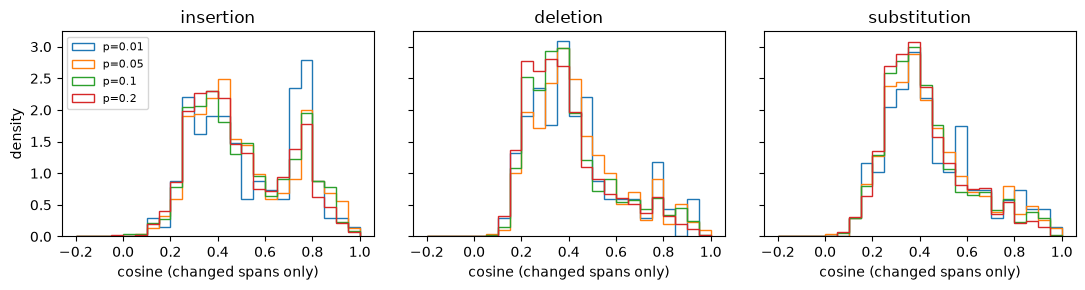

In [18]:
# what the cosines look like: the spread matters as much as the mean
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, op in zip(axes, ("ins", "del", "sub")):
    for pr in p2.rates:
        x = v[(v.op == op) & (v.p == pr) & v.text_changed].cosine
        ax.hist(x, bins=np.linspace(-0.2, 1, 25), histtype="step", label=f"p={pr}", density=True)
    ax.set_title({"ins": "insertion", "del": "deletion", "sub": "substitution"}[op]); ax.set_xlabel("cosine (changed spans only)")
axes[0].set_ylabel("density"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**How to read this (and what not to conclude).**

- Pairs whose text did not change have cosine exactly 1 and distance 0, so means over *all* valid pairs are pulled toward
  1 at low rates simply because few spans were hit. The histogram above is restricted to spans the noise changed.
- A low cosine means the pooled vector turned toward a different direction. It does **not** mean the meaning was lost,
  and a high cosine does not mean it was kept. This is the claim we keep separate from prediction in Workstream B.
- With one-piece spans (87% of the clean spans), cosine mostly compares one token's vector with the vector of its
  replacement pieces.
- Means are over valid pairs only. Always read them together with the undefined counts.

## 7. G6 — The 37-row static span audit

One row per condition (1 clean + 3 operations × 4 rates × 3 seeds). Every row reports **how many spans were selected, how many
gave a valid pair, and how many were undefined**, next to the means. Means are over valid pairs only.

Two kinds of mean are shown. `mean_cosine` is over all valid pairs, including spans the noise never touched (cosine exactly 1).
`mean_cosine_changed` is over valid pairs whose text was actually changed, which shows how far a span that *was* hit moved.

In [19]:
from src.geometry.drift import audit_table, seed_summary, plot_summary
audit = audit_table(pairs)
assert len(audit) == 37 and (audit.selected == 1000).all()
assert (audit.valid + audit.undefined == audit.selected).all() and audit.undefined.sum() == 62
assert audit.loc[audit.condition_id == "clean", ["mean_cosine", "mean_distance"]].round(12).values.tolist() == [[1.0, 0.0]]
audit.round(4)

,condition_id,operation,rate,seed,selected,valid,undefined,coverage,changed_spans,mean_cosine,mean_distance,mean_cosine_changed,mean_distance_changed
0,clean,clean,0.00,NaN,1000,1000,0,1.000,0,1.0000,0.0000,NaN,NaN
1,ins-p0.01-s11,insertion,0.01,11.0,1000,1000,0,1.000,39,0.9836,0.0363,0.5789,0.9298
2,ins-p0.01-s23,insertion,0.01,23.0,1000,1000,0,1.000,41,0.9794,0.0431,0.4967,1.0524
3,ins-p0.01-s47,insertion,0.01,47.0,1000,1000,0,1.000,56,0.9729,0.0566,0.5169,1.0106
4,ins-p0.05-s11,insertion,0.05,11.0,1000,1000,0,1.000,207,0.9065,0.2046,0.5483,0.9885
5,ins-p0.05-s23,insertion,0.05,23.0,1000,1000,0,1.000,215,0.8915,0.2266,0.4951,1.0539
6,ins-p0.05-s47,insertion,0.05,47.0,1000,1000,0,1.000,189,0.9053,0.1980,0.4990,1.0477
7,ins-p0.10-s11,insertion,0.10,11.0,1000,1000,0,1.000,372,0.8190,0.3810,0.5134,1.0243
8,ins-p0.10-s23,insertion,0.10,23.0,1000,1000,0,1.000,385,0.8104,0.3978,0.5075,1.0331
9,ins-p0.10-s47,insertion,0.10,47.0,1000,1000,0,1.000,379,0.8126,0.3939,0.5056,1.0393


## 8. G7 — Summaries across the three corruption seeds

For each operation and rate, the mean, minimum and maximum of the three seed-level results. The clean condition is one
dataset and is shown separately (cosine 1, distance 0), not as three runs.

**The min–max range is variation across three random corruptions of the same text.** It is not a confidence interval: no
model was retrained and no records were resampled.

In [20]:
summary = seed_summary(audit)
cols = ["operation", "rate", "valid_min", "undefined_max", "mean_cosine_mean", "mean_cosine_min", "mean_cosine_max",
        "mean_distance_mean", "mean_cosine_changed_mean"]
print("clean (single dataset): cosine = 1.000, distance = 0.000, 1000 valid / 0 undefined\n")
summary[cols].round(3)

clean (single dataset): cosine = 1.000, distance = 0.000, 1000 valid / 0 undefined



,operation,rate,valid_min,undefined_max,mean_cosine_mean,mean_cosine_min,mean_cosine_max,mean_distance_mean,mean_cosine_changed_mean
0,insertion,0.01,1000,0,0.979,0.973,0.984,0.045,0.531
1,insertion,0.05,1000,0,0.901,0.891,0.907,0.210,0.514
2,insertion,0.10,1000,0,0.814,0.810,0.819,0.391,0.509
3,insertion,0.20,1000,0,0.689,0.686,0.693,0.638,0.492
4,deletion,0.01,1000,0,0.974,0.971,0.978,0.052,0.427
5,deletion,0.05,998,2,0.883,0.881,0.886,0.237,0.435
6,deletion,0.10,994,6,0.782,0.772,0.790,0.432,0.412
7,deletion,0.20,983,17,0.638,0.626,0.645,0.708,0.391
8,substitution,0.01,1000,0,0.975,0.970,0.980,0.052,0.453
9,substitution,0.05,1000,0,0.882,0.878,0.891,0.235,0.441


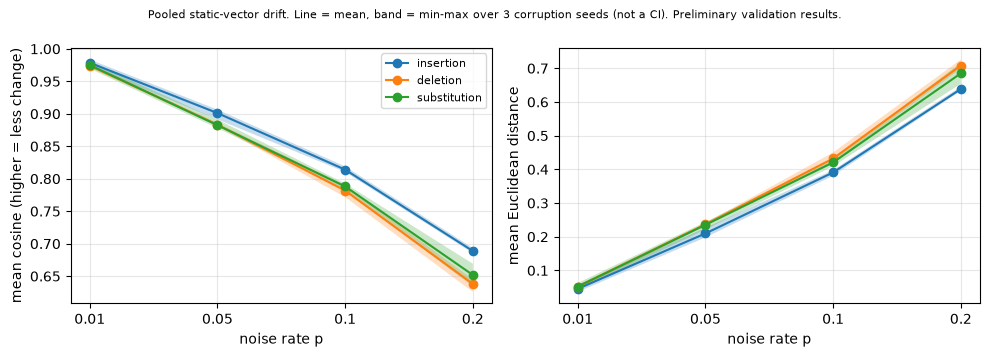

In [21]:
fig = plot_summary(summary, show=True)

**What this does and does not show (all preliminary validation results, one 22-record slice):**

- **Drift grows with the rate for all three operations.** Mean cosine falls from about 0.97–0.98 at p = 0.01 to about
  0.64–0.69 at p = 0.20, and mean distance rises from about 0.05 to about 0.64–0.71. The three seeds stay close together.
- **Most of that decline comes from how many spans were hit, not from each hit span moving further.** Among changed spans the
  mean cosine stays roughly flat as p grows (insertion about 0.49–0.53, deletion about 0.39–0.44, substitution about 0.42–0.45).
  Higher p mainly touches more spans.
- **Insertion drifts least per changed span.** This fits what G4 showed: an inserted letter often leaves the original
  letters in place, while deletion and substitution remove or replace them. We have not tested that explanation, and the
  difference between operations is modest.
- **Only deletion creates undefined pairs** (up to 17 of 1,000 spans per condition at p = 0.20). Deletion means therefore
  cover slightly fewer pairs.
- **No claim about meaning.** A lower cosine says the pooled static vector turned; it does not say meaning was lost, and a
  high cosine does not say it was kept. That question is for the prediction results.
- **Narrow sample.** 1,000 spans from 22 records (2 articles); 87% of clean spans are a single word piece.

## 9. G8 — Reproduce everything with the required script

The assignment asks for a program named `noise_vector_drift.py`. It runs the same pipeline end to end (spans, noisy twins, pooling,
metrics, audit, summary, figure) and writes the result files. Here we run it and check that it reproduces the tables above exactly.

In [22]:
import pandas.testing as pdt
from src.geometry.drift import run
out = run(verbose=False)                       # same code path as:  python noise_vector_drift.py
key = lambda d: d.sort_values("condition_id").reset_index(drop=True)
pdt.assert_frame_equal(key(out["audit"]), key(audit), check_exact=False, rtol=1e-9)
pdt.assert_frame_equal(out["summary"], summary, check_exact=False, rtol=1e-9)
print("script output == notebook tables (audit: 37 rows, summary: 12 rows)  -> OK")
print(json.dumps({k: out["info"][k] for k in ("spans_selected", "records_covered", "conditions", "pairs", "valid_pairs",
                                               "undefined_pairs", "identity_check_passed", "E_unchanged_after_run")}, indent=1))
for f in sorted(RESULTS_P3_DIR.rglob("*")):
    if f.is_file(): print(f"{f.relative_to(RESULTS_P3_DIR)!s:40} {f.stat().st_size:>9,} bytes")

script output == notebook tables (audit: 37 rows, summary: 12 rows)  -> OK
{
 "spans_selected": 1000,
 "records_covered": 22,
 "conditions": 37,
 "pairs": 37000,
 "valid_pairs": 36938,
 "undefined_pairs": 62,
 "identity_check_passed": true,
 "E_unchanged_after_run": true
}
figures/geometry_drift.png                 132,819 bytes
figures/neural_noise.png                   192,683 bytes
figures/neural_training.png                 93,278 bytes
geometry_run_info.json                         599 bytes
neural_condition_rows.csv                   14,968 bytes
neural_noise_summary.csv                     6,114 bytes
neural_run_info.json                         1,865 bytes
neural_training_history.csv                    753 bytes
neural_vs_ngram_change.csv                   3,200 bytes
ngram_control.csv                            4,883 bytes
noise_summary_geometry.csv                   3,390 bytes
span_pairs.parquet                         412,882 bytes
static_span_audit.csv                     

## Where we are

**Geometry workstream complete (G0–G8).** Frozen **E** (hash unchanged), 1,000 spans, verified noisy counterparts in 37
conditions, pooled vectors, cosine and distance for every valid pair, the 37-row audit, seed summaries and figure, and the
required script `noise_vector_drift.py` reproducing the tables.
Outputs are in `results/phase3/`. Remaining Phase 3 work belongs to Workstream B (next-token prediction) and the joint
n-gram comparison and write-up.

# Workstream B — Neural next-token prediction

Geometry measured how far a *static vector* moves. Now the second question: how does noise change **next-token prediction**?
These are different measurements, and a small vector change does not tell us how much a prediction changes.

**What the models do.** For every token in a record, the model sees the two tokens before it and gives a probability to the actual
next token. Two models, same network, different input:

| | input to the network | size |
|---|---|---|
| mean pooling | `(e1 + e2) / 2` | 768 numbers; word order is lost |
| concatenation | `[e1 ; e2]` | 1,536 numbers; word order is kept |

Then `h = ReLU(W1 x + b1)` with 64 hidden units, `z = W2 h + b2` over **K = 29,525** allowed outputs (the Assignment 2 output set:
the BERT vocabulary minus padding/CLS/SEP/MASK/unused entries, plus `[UNK]` and an end-of-record output), and a softmax. The embedding table **E** is
frozen: only `W1, b1, W2, b2` train. Settings are fixed by the assignment: Adam, learning rate 0.001, batch 128, at most 5 epochs, seed 101,
no dropout or weight decay. Both models train **once, on clean training text only**. The three corruption seeds only change the *evaluation* text.

The full run is `python neural_next_token.py` (about 4 to 7 minutes on a laptop CPU). This notebook reads its saved results, and re-computes some of them
from the saved weights to prove they match.

In [23]:
import torch
from src.phase2_config import load_phase2_config
from src.neural.run import build_output_space, load_records, load_control, summarise
from src.neural.data import encode_texts, BOS
from src.neural.model import NextTokenNet
from src.neural.evaluate import evaluate, to_tensors
from src.neural.figures import plot_training, plot_noise

cfgN = p3["neural"]
R = RESULTS_P3_DIR
neural = pd.read_csv(R / "neural_condition_rows.csv"); nsum = pd.read_csv(R / "neural_noise_summary.csv")
control = pd.read_csv(R / "ngram_control.csv"); hist = pd.read_csv(R / "neural_training_history.csv")
info = json.load(open(R / "neural_run_info.json"))
print("label:", info["label"]); print("results read from:", R)
print({k: info[k] for k in ("K_outputs", "torch", "device", "torch_threads", "deterministic_algorithms")})

label: preliminary validation results
results read from: /Users/samratrajsharma/Documents/School/Sem-3/NLP/Bert-Project/results/phase3
{'K_outputs': 29525, 'torch': '2.15.0', 'device': 'cpu', 'torch_threads': 1, 'deterministic_algorithms': True}


## 11. N0–N1 — Turning records into (context → next token) examples

For a record with pieces `w1 … wn` the examples are `(BOS,BOS)→w1`, `(BOS,w1)→w2`, …, `(w_{n-1},w_n)→EOS`. BOS means *beginning of sequence*: it only ever
appears as an **input**, and it is an all-zero vector (not a row of BERT's table). EOS means *end of sequence*: it is only ever an **output**. Every observed token
plus one EOS is scored, and the context starts fresh at each record: nothing is carried across records and no future tokens are used.

In [24]:
p2 = load_phase2_config()
pipe, vocab, vstats, hf_ids = build_output_space(p2)
train_rec, cond_rows = load_records()
inv_bert = {v: k for k, v in hf_ids.items()}
rec = train_rec[0]["text"]
toks = pipe.tokenize_batch([rec])[0]
seq = encode_texts([rec], pipe, vocab, hf_ids)
name_ctx = lambda i: "BOS" if i == BOS else inv_bert[i]
rows = [(name_ctx(a), name_ctx(b), vocab.tokens[t]) for (a, b), t in zip(seq.ctx[:5], seq.tgt[:5])]
rows += [(name_ctx(a), name_ctx(b), vocab.tokens[t]) for (a, b), t in zip(seq.ctx[-2:], seq.tgt[-2:])]
print(f"record {train_rec[0]['record_id']}: {len(toks)} pieces -> {seq.T} examples (pieces + one EOS)")
pd.DataFrame(rows, columns=["context 1", "context 2", "target"])

record wt2-train-000004: 105 pieces -> 106 examples (pieces + one EOS)


,context 1,context 2,target
0,BOS,BOS,the
1,BOS,the,game
2,the,game,began
3,game,began,development
4,began,development,in
5,',n,.
6,n,.,</s>


In [25]:
# the same targets as Assignment 2: counts must match exactly
ctrl = control.set_index("condition_id")["T"]
parity = neural[neural.model == "mean"].set_index("condition_id")["T"]
print("output set K                :", vocab.size, "(BERT vocab minus", vstats["excluded"], "excluded entries, plus the end-of-record output)")
print("training targets            :", json.load(open(DERIVED_P3_DIR / "neural_retained_records.json"))["train_targets"], "(500 clean training records)")
print("clean validation targets    :", int(parity["clean"]), " (Assignment 2 n-gram: ", int(ctrl["clean"]), ")")
print("all 37 conditions match the Assignment 2 target count:", bool((parity.sort_index() == ctrl.sort_index()).all()))
retained = json.load(open(DERIVED_P3_DIR / "neural_retained_records.json"))
print("retained records            :", retained["train_records"], "train,", retained["validation_records"], "validation; cap applied:", retained["cap_applied"])

output set K                : 29525 (BERT vocab minus 998 excluded entries, plus the end-of-record output)
training targets            : 35642 (500 clean training records)
clean validation targets    : 35971  (Assignment 2 n-gram:  35971 )
all 37 conditions match the Assignment 2 target count: True
retained records            : 500 train, 500 validation; cap applied: False


## 12. N2 — The two networks

Same layers, different input. **E** is held as a frozen lookup table: it is not a trainable parameter, is not in the optimizer and is not saved with the weights.
Concatenation has more input-layer weights (1,536 vs 768 inputs into the 64 hidden units), so any difference between the models cannot be credited only to word order.

In [26]:
rows = [{"model": m, "inputs m": 768 if m == "mean" else 1536, "trainable parameters": info["models"][m]["trainable"],
         "frozen (E)": info["models"][m]["frozen"], "formula 64m + 64 + 64K + K": 64*(768 if m == "mean" else 1536) + 64 + 64*vocab.size + vocab.size} for m in ("mean", "concat")]
pd.DataFrame(rows)

,model,inputs m,trainable parameters,frozen (E),formula 64m + 64 + 64K + K
0,mean,768,1968341,23440896,1968341
1,concat,1536,2017493,23440896,2017493


In [27]:
# Order test with the REAL trained weights: swap the two context tokens ("the game" vs "game the")
E_t = torch.from_numpy(np.array(E))
ids = lambda w: hf_ids[w]
ctx_a = torch.tensor([[ids("the"), ids("game")]]); ctx_b = torch.tensor([[ids("game"), ids("the")]])
for m in ("mean", "concat"):
    net = NextTokenNet(E_t, m, vocab.size, cfgN["hidden_size"])
    net.load_state_dict(torch.load(DERIVED_P3_DIR / "neural" / f"{m}_best.pt"))
    net.eval()
    with torch.no_grad():
        la, lb = net(ctx_a), net(ctx_b)
    top = lambda l: vocab.tokens[int(l.argmax())]
    print(f"{m:6}: largest change in the {vocab.size} scores after swapping = {float((la-lb).abs().max()):.4f};  top prediction {top(la)!r} vs {top(lb)!r}")

mean  : largest change in the 29525 scores after swapping = 0.0000;  top prediction 'the' vs 'the'
concat: largest change in the 29525 scores after swapping = 4.6449;  top prediction 'of' vs 'the'


The mean model gives *identical* scores for the swapped pair (it cannot see the order); the concatenation model does not. That is the one structural difference we are testing.

## 13. N3 — Training and picking the saved epoch

After each epoch we measure the loss on the **clean validation** records without updating anything, and keep the epoch with the lowest value (an exact tie keeps the earlier one).
Noisy results are never used to choose a model.

In [28]:
print("untrained validation loss:", {m: round(info["models"][m]["untrained_val_loss"], 3) for m in info["models"]}, " (uniform guessing = ln K = %.3f)" % np.log(vocab.size))
h = hist.copy(); h["kept"] = h.selected.map({True: "<- kept", False: ""})
h.round(4)[["model", "epoch", "train_loss", "val_loss", "val_accuracy", "kept"]]

untrained validation loss: {'mean': 10.297, 'concat': 10.289}  (uniform guessing = ln K = 10.293)


,model,epoch,train_loss,val_loss,val_accuracy,kept
0,mean,1,7.9131,7.5507,0.0866,
1,mean,2,6.7836,7.5032,0.0982,<- kept
2,mean,3,6.5746,7.5405,0.1120,
3,mean,4,6.4202,7.5793,0.1251,
4,mean,5,6.2969,7.6557,0.1274,
5,concat,1,7.6845,7.3197,0.1163,
6,concat,2,6.4703,7.2832,0.1381,<- kept
7,concat,3,6.1835,7.3472,0.1498,
8,concat,4,5.9862,7.4013,0.1567,
9,concat,5,5.8191,7.4707,0.1604,


In [29]:
fig = plot_training(hist)

**Reading this.** Training loss keeps falling, but validation loss is lowest at epoch 2 for both models and then rises: the networks start memorising the 500 training records
(35,642 targets against 29,525 possible outputs). Validation *accuracy* keeps creeping up even as the loss worsens, because the loss punishes confident wrong guesses.
The assignment says to select by validation loss, so epoch 2 is kept.

## 14. N4–N5 — Scoring 37 conditions with both models

Teacher-forced scoring: clean text is scored with clean contexts and clean targets, noisy text with noisy contexts and noisy targets, and the model's own guesses are never fed back.
Loss is **summed over every target in the condition** (including one EOS per record) and divided once by the target count: `H = S / T` in nats, `PP = exp(H)`,
accuracy = top-1 correct / T. Per-record perplexities are never averaged.

In [30]:
assert len(neural) == 74 and len(nsum) == 24
neural[neural.condition_id.isin(["clean", "ins-p0.10-s11", "del-p0.10-s11", "sub-p0.10-s11"])][
    ["model", "condition_id", "T", "H", "PP", "accuracy", "unk_share", "pieces_per_record"]].round(4).reset_index(drop=True)

,model,condition_id,T,H,PP,accuracy,unk_share,pieces_per_record
0,mean,clean,35971,7.5032,1813.8778,0.0982,0.0012,70.942
1,concat,clean,35971,7.2832,1455.6799,0.1381,0.0012,70.942
2,mean,ins-p0.10-s11,54940,8.7537,6334.0891,0.0558,0.0008,108.880
3,concat,ins-p0.10-s11,54940,8.6274,5582.5052,0.0743,0.0008,108.880
4,mean,del-p0.10-s11,44298,8.2417,3795.8478,0.0656,0.0010,87.596
5,concat,del-p0.10-s11,44298,8.1193,3358.7918,0.0902,0.0010,87.596
6,mean,sub-p0.10-s11,51454,8.6782,5873.3624,0.0566,0.0008,101.908
7,concat,sub-p0.10-s11,51454,8.5443,5137.5241,0.0780,0.0008,101.908


In [31]:
# Proof the saved weights reproduce the table: re-score three conditions from the saved models and compare with the CSV
chk = []
for m in ("mean", "concat"):
    net = NextTokenNet(E_t, m, vocab.size, cfgN["hidden_size"]); net.load_state_dict(torch.load(DERIVED_P3_DIR / "neural" / f"{m}_best.pt")); net.eval()
    for cid in ("clean", "ins-p0.10-s11", "del-p0.20-s47"):
        s_ = encode_texts([r["noisy_text"] for r in cond_rows[cid]], pipe, vocab, hf_ids)
        r_ = evaluate(net, *to_tensors(s_), chunk=cfgN["eval_chunk"])
        saved = neural[(neural.model == m) & (neural.condition_id == cid)].iloc[0]
        assert abs(r_["H"] - saved.H) < 1e-9 and abs(r_["accuracy"] - saved.accuracy) < 1e-12 and r_["T"] == saved["T"]
        chk.append((m, cid, round(r_["H"], 4), round(saved.H, 4)))
print("recomputed from saved weights == saved table for", len(chk), "model/condition pairs: OK")
pd.DataFrame(chk, columns=["model", "condition", "H recomputed", "H in table"])

recomputed from saved weights == saved table for 6 model/condition pairs: OK


,model,condition,H recomputed,H in table
0,mean,clean,7.5032,7.5032
1,mean,ins-p0.10-s11,8.7537,8.7537
2,mean,del-p0.20-s47,8.4901,8.4901
3,concat,clean,7.2832,7.2832
4,concat,ins-p0.10-s11,8.6274,8.6274
5,concat,del-p0.20-s47,8.4069,8.4069


In [32]:
# the 24-row noise summary: mean, min, max over the three corruption seeds; clean shown separately
cl = neural[neural.condition_id == "clean"].set_index("model")
print("clean (single dataset):", {m: (round(cl.H[m], 3), round(cl.PP[m], 1), round(cl.accuracy[m], 3)) for m in cl.index}, " (H, PP, accuracy)")
nsum[["model", "operation", "p", "H_mean", "H_min", "H_max", "PP_mean", "accuracy_mean", "accuracy_min", "accuracy_max", "dH_mean"]].round(3)

clean (single dataset): {'mean': (np.float64(7.503), np.float64(1813.9), np.float64(0.098)), 'concat': (np.float64(7.283), np.float64(1455.7), np.float64(0.138))}  (H, PP, accuracy)


,model,operation,p,H_mean,H_min,H_max,PP_mean,accuracy_mean,accuracy_min,accuracy_max,dH_mean
0,concat,insertion,0.01,7.496,7.488,7.501,1800.112,0.127,0.127,0.128,0.212
1,concat,insertion,0.05,8.132,8.118,8.140,3401.318,0.097,0.097,0.097,0.849
2,concat,insertion,0.10,8.624,8.618,8.627,5562.292,0.074,0.074,0.074,1.341
3,concat,insertion,0.20,9.167,9.151,9.177,9579.602,0.051,0.051,0.051,1.884
4,concat,deletion,0.01,7.415,7.408,7.420,1660.380,0.130,0.130,0.131,0.132
5,concat,deletion,0.05,7.806,7.803,7.809,2456.198,0.109,0.108,0.109,0.523
6,concat,deletion,0.10,8.108,8.095,8.119,3319.813,0.091,0.090,0.092,0.824
7,concat,deletion,0.20,8.402,8.396,8.407,4454.906,0.074,0.073,0.074,1.119
8,concat,substitution,0.01,7.494,7.486,7.502,1797.616,0.128,0.128,0.128,0.211
9,concat,substitution,0.05,8.104,8.101,8.107,3307.101,0.098,0.098,0.098,0.821


The min–max range is how much the result varies across **three random corruptions of the same text**. It is not a confidence interval: no model was retrained, so it says
nothing about variation across independently trained networks.

## 15. N6 — The Assignment 2 n-gram control

These 37 rows are the Assignment 2 interpolated WordPiece n-gram model (trained on the same 500 records), kept separate from the 74 neural rows. Its frozen interpolation weights
for this training set are `[1, 0, 0]`, which makes it the add-one **unigram** model: it ignores the two previous tokens entirely. We use it as-is because the assignment asks for the
Assignment 2 baseline.

In [33]:
csum = summarise(control, ["model", "operation", "p"], ["H", "PP", "dH"])
c0 = control[control.condition_id == "clean"].iloc[0]
print(f"clean: n-gram H = {c0.H:.3f} (PP {c0.PP:.0f})   mean-pool H = {cl.H['mean']:.3f} (PP {cl.PP['mean']:.0f})   concat H = {cl.H['concat']:.3f} (PP {cl.PP['concat']:.0f})")
assert len(control) == 37
cmp_ = nsum.pivot_table(index=["operation", "p"], columns="model", values="dH_mean").join(csum.set_index(["operation", "p"])["dH_mean"].rename("ngram"))
cmp_["neural worse than n-gram (mean | concat)"] = [f"{a > c} | {b > c}" for a, b, c in zip(cmp_["mean"], cmp_["concat"], cmp_["ngram"])]
cmp_.rename(columns={"mean": "mean-pool dH", "concat": "concat dH", "ngram": "n-gram dH"}).round(3)

clean: n-gram H = 7.549 (PP 1898)   mean-pool H = 7.503 (PP 1814)   concat H = 7.283 (PP 1456)


concat dH  mean-pool dH  n-gram dH  \
operation    p                                          
deletion     0.01      0.132         0.116      0.094   
             0.05      0.523         0.461      0.373   
             0.10      0.824         0.725      0.597   
             0.20      1.119         0.982      0.831   
insertion    0.01      0.212         0.194      0.151   
             0.05      0.849         0.785      0.608   
             0.10      1.341         1.249      0.970   
             0.20      1.884         1.783      1.385   
substitution 0.01      0.211         0.193      0.150   
             0.05      0.821         0.758      0.592   
             0.10      1.268         1.180      0.927   
             0.20      1.757         1.658      1.314   

                  neural worse than n-gram (mean | concat)  
operation    p                                              
deletion     0.01                              True | True  
             0.05                              True | True  
             0.10                              True | True  
             0.20                              True | True  
insertion    0.01                              True | True  
             0.05                              True | True  
             0.10                              True | True  
             0.20                              True | True  
substitution 0.01                              True | True  
             0.05                              True | True  
             0.10                              True | True  
             0.20                              True | True

In [34]:
fig = plot_noise(nsum, csum)

In [35]:
# absolute loss, not just change: where is each model better in raw loss on the noisy text?
absH = nsum.pivot_table(index=["operation", "p"], columns="model", values="H_mean").join(csum.set_index(["operation", "p"])["H_mean"].rename("ngram"))
absH["best (lowest loss)"] = absH[["mean", "concat", "ngram"]].idxmin(axis=1)
absH.round(3)

concat   mean  ngram best (lowest loss)
operation    p                                            
deletion     0.01   7.415  7.619  7.642             concat
             0.05   7.806  7.964  7.922             concat
             0.10   8.108  8.229  8.145             concat
             0.20   8.402  8.485  8.380              ngram
insertion    0.01   7.496  7.697  7.699             concat
             0.05   8.132  8.288  8.156             concat
             0.10   8.624  8.752  8.519              ngram
             0.20   9.167  9.286  8.933              ngram
substitution 0.01   7.494  7.697  7.698             concat
             0.05   8.104  8.261  8.141             concat
             0.10   8.551  8.683  8.475              ngram
             0.20   9.040  9.161  8.863              ngram

## 16. N7 — Tokenization diagnostics: why a number can move for a reason other than prediction quality

Loss measures how likely the model finds the *observed* text after tokenization. A lower noisy loss could come from easier targets or more unknown tokens, so always look at what the tokenizer did.

In [36]:
d = neural[neural.model == "mean"].copy()
diag = d.groupby(["operation", "p"], sort=False).agg(targets_T=("T", "mean"), pieces_per_record=("pieces_per_record", "mean"),
                                                       continuation_share=("continuation_share", "mean"), unk_share=("unk_share", "mean")).round(4)
print("All three operations INCREASE the number of targets T (typos break words into more word pieces: clean 71 pieces per record, up to 139 under 20% insertion). A noisy condition is therefore scored on a different, longer target sequence, so loss per target is not a like-for-like comparison with clean.")
print("noisy condition with lower loss than clean, any model:", bool((neural[neural.operation != "clean"].dH < 0).any()))
diag

All three operations INCREASE the number of targets T (typos break words into more word pieces: clean 71 pieces per record, up to 139 under 20% insertion). A noisy condition is therefore scored on a different, longer target sequence, so loss per target is not a like-for-like comparison with clean.
noisy condition with lower loss than clean, any model: False


targets_T  pieces_per_record  continuation_share  \
operation    p                                                         
clean        0.00  35971.0000            70.9420              0.0758   
insertion    0.01  38094.0000            75.1880              0.1280   
             0.05  46075.6667            91.1513              0.2807   
             0.10  55006.6667           109.0133              0.3986   
             0.20  70141.0000           139.2820              0.5293   
deletion     0.01  37125.0000            73.2500              0.1052   
             0.05  40897.6667            80.7953              0.1901   
             0.10  44282.3333            87.5647              0.2547   
             0.20  47421.6667            93.8433              0.3102   
substitution 0.01  37839.0000            74.6780              0.1221   
             0.05  44644.6667            88.2893              0.2574   
             0.10  51553.0000           102.1060              0.3579   
             0.20  62095.3333           123.1907              0.4678   

                   unk_share  
operation    p                
clean        0.00     0.0012  
insertion    0.01     0.0011  
             0.05     0.0009  
             0.10     0.0008  
             0.20     0.0006  
deletion     0.01     0.0012  
             0.05     0.0011  
             0.10     0.0010  
             0.20     0.0009  
substitution 0.01     0.0011  
             0.05     0.0010  
             0.10     0.0008  
             0.20     0.0007

## 17. What this shows, and what it does not (preliminary validation results)

- **Noise raises loss and lowers accuracy for both models, for all three operations, at every rate.** The effect grows with the rate. Clean: mean pooling PP ≈ 1,814 with 9.8% top-1 accuracy, concatenation PP ≈ 1,456 with 13.8%.
  At p = 0.20 insertion, loss rises by about 1.8 nats (accuracy falls to 3.9% and 5.1%).
- **Neither neural model deteriorates less than the n-gram control.** The increase in loss over each model's own clean result is larger for both neural models than for the control in every operation × rate cell.
  The control is a unigram, so it never depended on the previous tokens; the neural models also lose the quality of their context when the preceding tokens are corrupted. We have not isolated that explanation.
- **Concatenation is better in absolute loss and accuracy in every cell, but its loss rises slightly more than the mean model's.** Order information helps on clean text, and also gives noise more to disturb. Because concatenation has twice the input weights, we cannot credit this to word order alone.
- **Absolute loss tells a mixed story against the control.** Concatenation has the lowest loss in 7 of the 12 operation × rate cells and the n-gram control in the other 5 (mean pooling in none). The control wins at the heavier noise levels, so "which model is best" depends on the noise.
- **Insertion hurts most, deletion least** (at the same p), in loss for all models.
- **Overfitting limits all of this.** The clean validation loss is lowest after 2 epochs and the networks are fitted to only 500 records. This is a small, controlled study, not a demonstration of a neural advantage.
- **Variation across seeds is small, but it is only variation across three random corruptions** of one trained model per type, not a confidence interval.
- **Vector drift versus prediction change** (the assignment's third question, counterexamples) is the next step; this notebook only reports each side.

## Where we are

**Geometry (G0–G8) and neural prediction (N0–N7) are both done.** Outputs are in `results/phase3/` (neural: `neural_condition_rows.csv` 74 rows, `neural_noise_summary.csv` 24 rows,
`ngram_control.csv` 37 rows, `neural_vs_ngram_change.csv`, `neural_training_history.csv`, `neural_run_info.json`, figures) and `derived/phase3/` (retained records, best weights).
Still ahead in the assignment: interpret counterexamples where vector drift and prediction change disagree, cross-verify each other's code, and extend the paper.